### Import Libraries

In [25]:
# for manipulations
import numpy as np
import pandas as pd

In [26]:
# for data visualizations
import matplotlib.pyplot as plt
plt.rcParams['axes.autolimit_mode'] = 'round_numbers'
plt.style.use('fivethirtyeight')

In [27]:
# lets import the warnings library so that we can avoid warnings
import warnings
warnings.filterwarnings('ignore')

In [28]:
# Custom Function
from custom_function import *

In [29]:
# For Normalization
from sklearn.preprocessing import MinMaxScaler

### Loading

#### 1. Food Price

In [30]:
food_price = get_dataset('\\Datasets\\wfp_food_prices_mmr(Cleaned).csv')
food_price.drop(['latitude', 'longitude'],  axis='columns', inplace=True)
food_price.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
0,1/15/2008,Kachin,Myitkyina,Wai Maw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,400.00,0.2247
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
3,1/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448


In [31]:
food_price = food_price[['date', 'price']]
food_price['date'] = pd.to_datetime(food_price['date'])
food_price.columns = ['date', 'food_price']
food_price = food_price.set_index('date')
food_price = food_price.resample('AS-JAN').mean()
food_price.head()

,food_price
date,
2008-01-01,1002.766567
2009-01-01,805.337847
2010-01-01,900.166229
2011-01-01,972.709289
2012-01-01,832.871728


#### 2. Inflation Dataset

In [32]:
temp_inflation = get_dataset('\\Datasets\\inflation.csv')
temp_inflation.head()

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
0,Aruba,ABW,"Inflation, GDP deflator (annual %)",NY.GDP.DEFL.KD.ZG,NaN,NaN,NaN,NaN,NaN,NaN,...,3.107301,0.789086,3.286686,2.003480,0.439924,-1.371485,1.614052,NaN,NaN,NaN
1,Africa Eastern and Southern,AFE,"Inflation, GDP deflator (annual %)",NY.GDP.DEFL.KD.ZG,NaN,1.861701,0.979878,3.285364,3.726978,3.569951,...,9.430270,6.992016,5.844111,5.401164,5.366462,6.400900,5.217431,4.095047,4.252789,5.373589
2,Afghanistan,AFG,"Inflation, GDP deflator (annual %)",NY.GDP.DEFL.KD.ZG,NaN,NaN,NaN,NaN,NaN,NaN,...,16.593347,7.301756,4.822785,0.566945,2.447563,-2.197526,2.403656,2.071349,6.521480,7.821667
3,Africa Western and Central,AFW,"Inflation, GDP deflator (annual %)",NY.GDP.DEFL.KD.ZG,NaN,3.336148,2.432663,3.013917,2.906178,2.752432,...,8.789841,4.730095,1.573135,0.280788,1.992846,1.784172,1.759106,2.639372,1.582290,1.128352
4,Angola,AGO,"Inflation, GDP deflator (annual %)",NY.GDP.DEFL.KD.ZG,NaN,NaN,NaN,NaN,NaN,NaN,...,31.771549,7.255670,2.839789,3.560821,-3.518386,21.774240,22.614512,29.065954,28.090677,9.385221


In [33]:
temp_inflation = temp_inflation[temp_inflation['Country Code'] == 'MMR']
temp_inflation

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
160,Myanmar,MMR,"Inflation, GDP deflator (annual %)",NY.GDP.DEFL.KD.ZG,NaN,NaN,1.026439,0.796397,-1.36952,-1.078582,...,8.677799,6.435466,3.796992,4.265207,8.374897,-2.651352,5.372901,5.445659,6.265219,5.057


In [34]:
date = temp_inflation.columns
date = date[4:]
date

Index(['1960', '1961', '1962', '1963', '1964', '1965', '1966', '1967', '1968',
       '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977',
       '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986',
       '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995',
       '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004',
       '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013',
       '2014', '2015', '2016', '2017', '2018', '2019', '2020'],
      dtype='object')

In [35]:
date.shape

(61,)

In [36]:
inflation_rate = temp_inflation.copy()
inflation_rate = inflation_rate[date]
inflation_rate = inflation_rate.values
inflation_rate

array([[        nan,         nan,  1.02643906,  0.79639732, -1.36951981,
        -1.07858166,  2.54277287,  9.68125025,  8.61009607,  2.20580433,
         0.59849636, -1.87189724, -0.76692956,  5.36836719, 35.17250032,
        31.55002609, 13.05565578,  5.70623409,  1.33905391,  3.27509457,
         3.31875996,  2.88443076,  3.86618562,  2.62910853,  2.24963653,
         2.01728103,  4.05134484, 13.92474184, 22.8170357 , 44.81432889,
        33.34664997, 21.18035619, 23.23770625, 29.70587629, 27.96119523,
        20.64666485, 21.50000782, 29.06765889, 35.00444185, 28.3523645 ,
        11.02653052, 14.37463854, 34.60624105, 28.71970752, 10.72224821,
        12.01365725, 20.36748855, 22.59392778, 17.76433037,  8.76184776,
         6.02587342,  8.67779913,  6.43546634,  3.79699158,  4.26520662,
         8.37489724, -2.65135241,  5.37290102,  5.44565944,  6.26521866,
         5.05700034]])

In [37]:
date = pd.to_datetime(date, format='%Y')

In [38]:
inflation_rate = inflation_rate[0]
inflation_rate.shape

(61,)

In [39]:
inflation = pd.DataFrame()
inflation['inflation_rate'] = inflation_rate
inflation

,inflation_rate
0,NaN
1,NaN
2,1.026439
3,0.796397
4,-1.369520
...,...
56,-2.651352
57,5.372901
58,5.445659
59,6.265219


In [40]:
inflation['date']=date
inflation = inflation.set_index('date')
inflation.columns=['inflation_rate']
inflation.head()

,inflation_rate
date,
1960-01-01,NaN
1961-01-01,NaN
1962-01-01,1.026439
1963-01-01,0.796397
1964-01-01,-1.369520


In [41]:
inflation.dropna(inplace=True)
inflation.head()

,inflation_rate
date,
1962-01-01,1.026439
1963-01-01,0.796397
1964-01-01,-1.369520
1965-01-01,-1.078582
1966-01-01,2.542773


### Merge inflation_rate and food_price

In [42]:
food_inflation= food_price.join(inflation, how='inner')
food_inflation

,food_price,inflation_rate
date,,
2008-01-01,1002.766567,17.764330
2009-01-01,805.337847,8.761848
2010-01-01,900.166229,6.025873
2011-01-01,972.709289,8.677799
2012-01-01,832.871728,6.435466
2013-01-01,914.454042,3.796992
2014-01-01,1634.163191,4.265207
2015-01-01,1885.676491,8.374897
2016-01-01,2105.188314,-2.651352


### Correlation

In [43]:
correlation=food_inflation['food_price'].corr(food_inflation['inflation_rate'])
correlation

-0.40256894109277636

### Make scatter plot

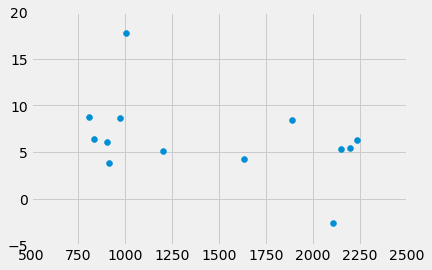

In [44]:
plt.scatter(food_inflation['food_price'],food_inflation['inflation_rate'])
plt.show()

<span style="color:red">There is a relation between Food Price and Inflation</span>

### Normalization

In [45]:
date = food_inflation.index

In [46]:
scaler = MinMaxScaler()

In [47]:
food_inflation = scaler.fit_transform(food_inflation)
food_inflation = pd.DataFrame(food_inflation)
food_inflation['date'] = date
food_inflation.set_index('date', inplace=True)
food_inflation.columns = ['food_price', 'inflation_rate']
food_inflation.head()

,food_price,inflation_rate
date,,
2008-01-01,0.138512,1.000000
2009-01-01,0.000000,0.559041
2010-01-01,0.066530,0.425027
2011-01-01,0.117424,0.554924
2012-01-01,0.019317,0.445090


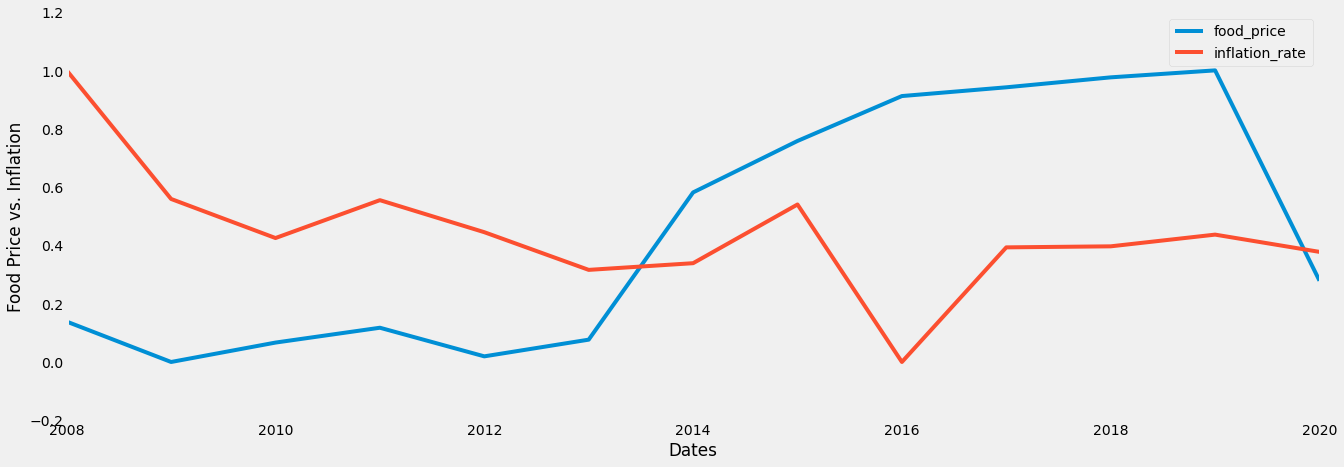

In [48]:
line_ax = food_inflation.plot(kind='line', figsize=(20, 7))
line_ax.set_ylabel('Food Price vs. Inflation')
line_ax.set_xlabel('Dates')
line_ax.grid()

<span style="color:red">There is negative relation between Food Price and Inflation Rate</span>